In [3]:
df = pd.read_csv("../data/raw/ai4i2020.csv")

In [4]:
df.head()


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.shape


(10000, 14)

In [6]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [8]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [9]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [10]:
df["Machine failure"].value_counts(normalize=True) * 100


Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

In [11]:
df.isnull().sum()


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [12]:
df.isnull().sum().sum()

np.int64(0)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [15]:
df["Type"].value_counts(normalize=True) * 100


Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64

In [16]:
df.groupby("Type")["Machine failure"].mean() * 100

Type
H    2.093719
L    3.916667
M    2.769436
Name: Machine failure, dtype: float64

In [17]:
import matplotlib.pyplot as plt

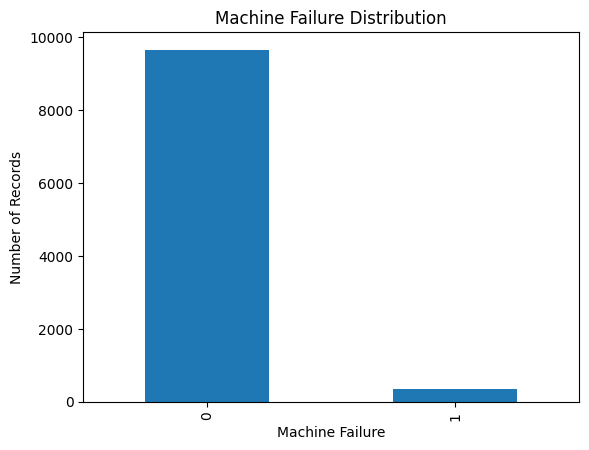

In [18]:
df["Machine failure"].value_counts().plot(kind="bar")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Records")

plt.show()

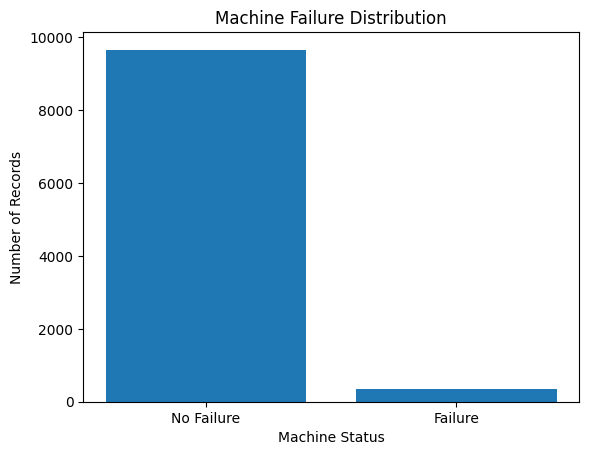

In [19]:
failure_counts = df["Machine failure"].value_counts()

plt.bar(
    ["No Failure", "Failure"],
    [failure_counts[0], failure_counts[1]]
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Status")
plt.ylabel("Number of Records")

plt.show()

In [20]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [21]:
df[numerical_features].describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


In [22]:
df.groupby("Machine failure")[numerical_features].mean()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


In [23]:
df["Temperature difference"] = (
    df["Process temperature [K]"]
    - df["Air temperature [K]"]
)

In [24]:
df.groupby("Machine failure")["Temperature difference"].mean()

Machine failure
0    10.021571
1     9.403835
Name: Temperature difference, dtype: float64

In [25]:
df["Machine failure"].value_counts(normalize=True) * 100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

In [26]:
df.groupby("Machine failure")[numerical_features].mean()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


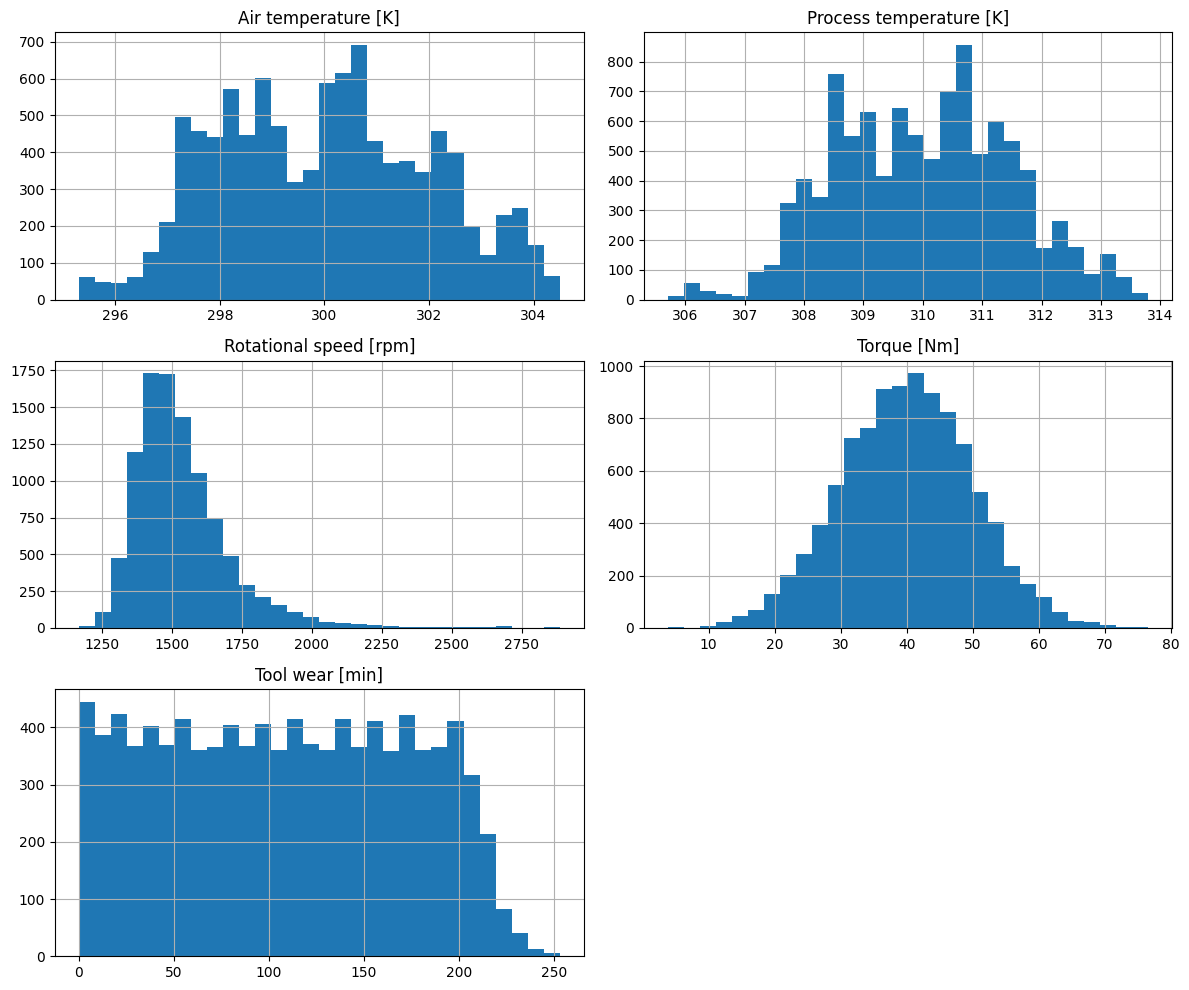

In [27]:
df[numerical_features].hist(figsize=(12, 10), bins=30)

plt.tight_layout()
plt.show()

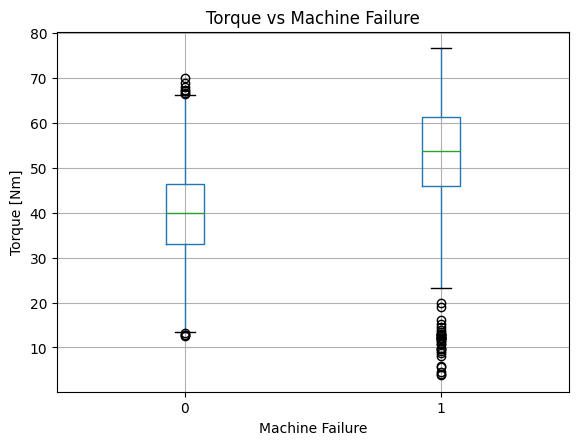

In [28]:
df.boxplot(
    column="Torque [Nm]",
    by="Machine failure"
)

plt.title("Torque vs Machine Failure")
plt.suptitle("")
plt.xlabel("Machine Failure")
plt.ylabel("Torque [Nm]")
plt.show()

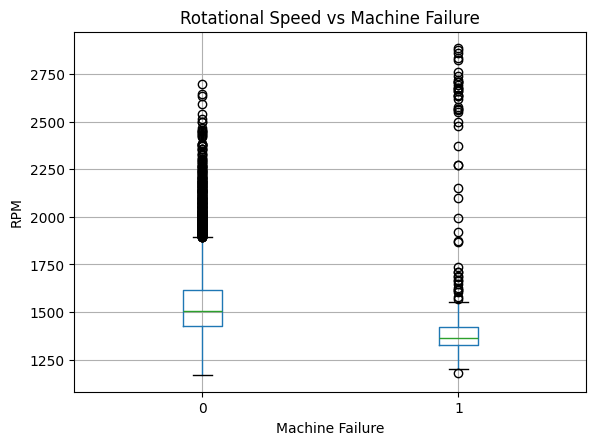

In [29]:
df.boxplot(
    column="Rotational speed [rpm]",
    by="Machine failure"
)

plt.title("Rotational Speed vs Machine Failure")
plt.suptitle("")
plt.xlabel("Machine Failure")
plt.ylabel("RPM")
plt.show()

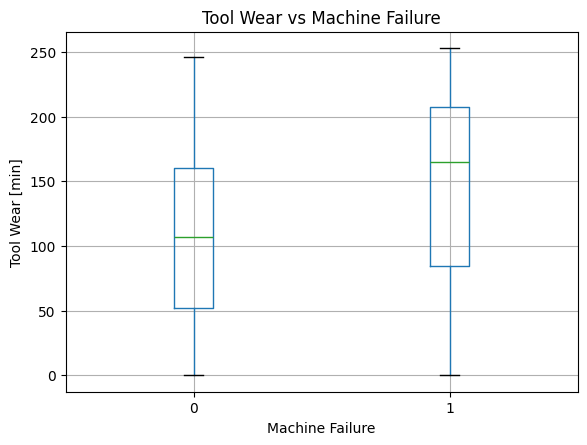

In [30]:
df.boxplot(
    column="Tool wear [min]",
    by="Machine failure"
)

plt.title("Tool Wear vs Machine Failure")
plt.suptitle("")
plt.xlabel("Machine Failure")
plt.ylabel("Tool Wear [min]")
plt.show()

In [31]:
failure_comparison = df.groupby("Machine failure")[numerical_features].mean()

failure_comparison

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717
1,300.886431,310.290265,1496.486726,50.168142,143.781711


In [32]:
failure_comparison.T

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


In [33]:
correlation_matrix = df[
    numerical_features + ["Machine failure"]
].corr()

correlation_matrix

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


In [34]:
correlation_matrix["Machine failure"].sort_values(ascending=False)

Machine failure            1.000000
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64

In [35]:
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df[failure_modes].sum()

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

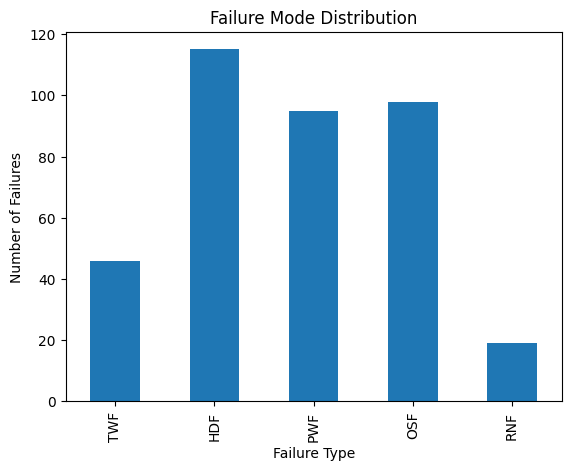

In [36]:
df[failure_modes].sum().plot(kind="bar")

plt.title("Failure Mode Distribution")
plt.xlabel("Failure Type")
plt.ylabel("Number of Failures")

plt.show()

In [37]:
df["Temperature difference"] = (
    df["Process temperature [K]"]
    - df["Air temperature [K]"]
)

In [38]:
numerical_features_extended = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference"
]

In [39]:
df.groupby("Machine failure")[numerical_features_extended].mean()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference
Machine failure,,,,,,
0,299.973999,309.995570,1540.260014,39.629655,106.693717,10.021571
1,300.886431,310.290265,1496.486726,50.168142,143.781711,9.403835


In [40]:
import numpy as np

In [41]:
df["Power [W]"] = (
    df["Torque [Nm]"]
    * 2
    * np.pi
    * df["Rotational speed [rpm]"]
    / 60
)

In [42]:
df[["Power [W]", "Machine failure"]].head()

,Power [W],Machine failure
0,6951.590560,0
1,6826.722724,0
2,7749.387543,0
3,5927.504659,0
4,5897.816608,0


In [1]:
print("Predictive Maintenance Project Started")

Predictive Maintenance Project Started


In [2]:
import pandas as pd